# Bài thực hành 4 — Encoder–Decoder và Attention



In [2]:
# Import thư viện
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

In [3]:
import gc
import math
from itertools import islice
from IPython.display import display

In [4]:
# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
elif Path('/kaggle/working').is_dir():
    raise RuntimeError('Phiên Kaggle chưa bật GPU. Chọn GPU trong Session options rồi chạy lại.')

PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4


In [5]:
cfg = dict(
    emb=256, hidden=256, layers=3,
    dropout=0.3, batch=32,
    micro_batch=32 if device.type == "cuda" and
        torch.cuda.get_device_properties(0).total_memory >= 12 * 1024**3 else 8,
    lr=1e-3, teacher_ratio=0.5, epochs=10,
    max_words=50, vocab_limit=10000, min_freq=2,
)
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
display(pd.Series(cfg, name='Giá trị').to_frame())

,Giá trị
emb,256.000
hidden,256.000
layers,3.000
dropout,0.300
batch,32.000
micro_batch,32.000
lr,0.001
teacher_ratio,0.500
epochs,10.000
max_words,50.000


In [6]:
base = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
input_root = Path('/kaggle/input')
input_folders = sorted({p.parent for p in input_root.rglob('small-train.json')}) if input_root.is_dir() else []
data_folder = next((p for p in input_folders
                    if all((p / f'small-{s}.json').is_file() for s in ['train', 'dev', 'test'])), None)
DATA = data_folder or (Path('/tmp/small-phomt') if input_root.is_dir() else base / 'data')
ART = base / 'artifacts' / 'assignment'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
names = {'none': 'Không attention', 'bahdanau': 'Bahdanau', 'luong': 'Luong'}
print('Dữ liệu:', DATA)
print('Kết quả:', ART)

Dữ liệu: /tmp/small-phomt
Kết quả: /kaggle/working/artifacts/assignment


## 2. Dữ liệu small-PhoMT


In [7]:
# Danh sách tệp: tên, link tải và mã SHA-256
DATA_FILES = [{'file': 'small-train.json',
  'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
  'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
 {'file': 'small-dev.json',
  'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
  'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
 {'file': 'small-test.json',
  'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
  'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'}]

In [8]:
# Tải tệp còn thiếu, rồi kiểm tra SHA-256 của cả ba tệp
for item in DATA_FILES:
    path = DATA/item['file']
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Nguồn tải đổi hoặc trả về HTML: '+item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: '+item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')

3/3 tệp dữ liệu khớp SHA-256.


In [9]:
# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))

['tôi', 'yêu', 'bạn']


In [10]:
# Đọc ba tệp, giữ cặp có cả hai phía dài từ 1 đến max_words token
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA/f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and \
                1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(split, '| tệp gốc:', len(raw[split]),
          '| sau lọc:', len(filtered[split]))

train | tệp gốc: 20000 | sau lọc: 18607
dev | tệp gốc: 2000 | sau lọc: 1901
test | tệp gốc: 2000 | sau lọc: 1786


In [11]:
data_summary = pd.DataFrame([
    {'Tập': split, 'Ban đầu': len(raw[split]), 'Sau lọc': len(filtered[split])}
    for split in ['train', 'dev', 'test']
])
display(data_summary)
train_rows, dev_rows = filtered['train'], filtered['dev']

,Tập,Ban đầu,Sau lọc
0,train,20000,18607
1,dev,2000,1901
2,test,2000,1786


### Từ điển và batch

In [12]:
# Hàm xây từ điển: 4 token đặc biệt + token xuất hiện ít nhất min_freq lần
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}

In [13]:
# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

Từ điển Anh/Việt: 8943 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}


In [14]:
def encode(seq, vocab):
    return [vocab.get(token, UNK) for token in seq]

In [15]:
# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

In [16]:
def loader(rows, shuffle=False, seed=42):
    return DataLoader(
        rows, batch_size=cfg['micro_batch'], shuffle=shuffle,
        collate_fn=collate, num_workers=0,
        pin_memory=device.type == 'cuda',
        generator=torch.Generator().manual_seed(seed),
    )

In [17]:
def unknown_rate(rows, field, vocab):
    total = sum(len(row[field]) for row in rows)
    unknown = sum(token not in vocab for row in rows for token in row[field])
    return unknown / total

display(pd.DataFrame([
    {'Tập': split,
     'UNK nguồn (%)': 100 * unknown_rate(filtered[split], 'src', src_vocab),
     'UNK đích (%)': 100 * unknown_rate(filtered[split], 'tgt', tgt_vocab)}
    for split in ['train', 'dev']
]).round(2))

,Tập,UNK nguồn (%),UNK đích (%)
0,train,2.12,0.66
1,dev,8.15,2.50


## 3. Các thành phần mô hình

Encoder và decoder là LSTM một chiều 3 lớp. Encoder dùng packing để
PAD không ảnh hưởng trạng thái cuối; cả hidden state và cell state được
truyền sang decoder. `memory` chứa đầu ra tại mọi vị trí nguồn để attention
có thể truy cập lại trong lúc dịch.

In [18]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state

In [19]:
# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def project(self, memory):
        return self.Wk(memory) if self.mode == 'bahdanau' else self.W(memory)

    def forward(self, query, memory, mask, projected=None):
        projected = self.project(memory) if projected is None else projected
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + projected)
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(projected,
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

### Decoder


In [20]:
# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding, projected=None):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask, projected)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask, projected)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights

In [21]:
# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        projected = self.decoder.attn.project(memory) if self.mode != 'none' else None
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding, projected)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

In [22]:
def make_seq2seq(mode):
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **model_cfg).to(device)

### Giải mã và ROUGE-L

Huấn luyện dùng teacher forcing 0,5. Khi dịch, mô hình nhận câu nguồn,
bắt đầu từ BOS, tự chọn token có logit lớn nhất và dừng tại EOS hoặc sau
51 bước.

In [23]:
# Sinh từng token bằng argmax đến khi mọi câu gặp EOS hoặc hết max_steps
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    projected = model.decoder.attn.project(memory) if model.mode != 'none' else None
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding, projected)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights

In [24]:
# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)

In [25]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
print(UnicodeTokens().tokenize('Tiếng Việt có dấu'))

['tiếng', 'việt', 'có', 'dấu']


In [26]:
# Trung bình ROUGE-L theo câu, kèm BLEU corpus để tham khảo
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))

## 4. Huấn luyện và lưu kết quả

Adam với learning rate 0,001, gradient clipping 1,0 và tối đa 10 epoch.
Chọn checkpoint theo ROUGE-L dev cao nhất; nếu bằng nhau chọn dev-NLL
thấp hơn. Dev-NLL dùng teacher forcing hoàn toàn, còn ROUGE-L được tính
từ bản dịch tự sinh. 

In [27]:
@torch.no_grad()
def evaluate(model, rows, with_loss=True):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src = b['src'].to(device)
        if with_loss:
            tgt = b['tgt'].to(device)
            gold = tgt[:, 1:]
            logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
            nll += nn.functional.cross_entropy(
                logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1),
                ignore_index=PAD, reduction='sum').item()
            count += int((gold != PAD).sum())
            del logits
        ids, _ = generate(model, src, b['lengths'], cfg['max_words'] + 1)
        hypotheses.extend(decode(row) for row in ids.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    if with_loss:
        metrics['dev_nll'] = nll / count
    return metrics, hypotheses

In [28]:
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, token_total = 0.0, 0
    batches = iter(train_loader)
    accumulation = math.ceil(cfg['batch'] / cfg['micro_batch'])
    updates = math.ceil(len(train_loader) / accumulation)
    for update in range(updates):
        group = list(islice(batches, accumulation))
        group_tokens = sum(int((b['tgt'][:, 1:] != PAD).sum()) for b in group)
        optimizer.zero_grad(set_to_none=True)
        for b in group:
            src, tgt = b['src'].to(device), b['tgt'].to(device)
            logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
            loss_sum = nn.functional.cross_entropy(
                logits.reshape(-1, len(tgt_vocab)), tgt[:, 1:].reshape(-1),
                ignore_index=PAD, reduction='sum')
            (loss_sum / group_tokens).backward()
            loss_total += loss_sum.item()
            del logits, loss_sum
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        token_total += group_tokens
        if (update + 1) % 100 == 0:
            print(f'  batch {update + 1}/{updates}, loss={loss_total/token_total:.4f}')
    return loss_total / token_total

In [29]:
run_info = dict(
    config=cfg, seed=42, src_vocab=src_vocab, tgt_vocab=tgt_vocab,
    normalization='NFC; remove BOM; lowercase; whitespace',
    data_files=DATA_FILES,
    train_ids=[r['id'] for r in train_rows],
    dev_ids=[r['id'] for r in dev_rows],
)
run_path = ART / 'metadata.json'
if run_path.exists():
    saved_info = json.loads(run_path.read_text(encoding='utf-8'))
    if saved_info != run_info:
        raise ValueError('Cấu hình hoặc dữ liệu đã đổi. Chọn thư mục ART mới cho lần chạy này.')
else:
    run_path.write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding='utf-8')

In [30]:
def save_checkpoint(payload, path):
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def fit(model, mode):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    best_path, last_path = ART / f'{mode}_best.pt', ART / f'{mode}_last.pt'
    history, best_key, best_epoch, start_epoch = [], (-1.0, -float('inf')), 0, 1
    if last_path.exists():
        last = torch.load(last_path, map_location=device, weights_only=True)
        model.load_state_dict(last['model'])
        optimizer.load_state_dict(last['optimizer'])
        history = last['history']
        best_key, best_epoch = tuple(last['best_key']), last['best_epoch']
        start_epoch = last['epoch'] + 1
        del last
        print(f'Tiếp tục từ epoch {start_epoch}')
    for epoch in range(start_epoch, cfg['epochs'] + 1):
        seed_all(42 + epoch)
        train_loader = loader(train_rows, shuffle=True, seed=42 + epoch)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        measured, _ = evaluate(model, dev_rows)
        record = dict(epoch=epoch, train_loss=train_loss, seconds=seconds, **measured)
        history.append(record)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            save_checkpoint(dict(model=model.state_dict(), epoch=epoch,
                                 metrics=measured, mode=mode), best_path)
        save_checkpoint(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                             epoch=epoch, history=history, best_key=list(best_key),
                             best_epoch=best_epoch), last_path)
        pd.DataFrame(history).to_csv(ART / f'{mode}_history.csv', index=False)
        print(f'{names[mode]} | epoch {epoch}/{cfg["epochs"]} | '
              f'loss={train_loss:.4f} | dev ROUGE-L={measured["rougeL_f1"]:.4f} | '
              f'{seconds:.0f} giây train')
    best = torch.load(best_path, map_location=device, weights_only=True)
    model.load_state_dict(best['model'])
    model.eval()
    return pd.DataFrame(history), best_epoch

`*_last.pt` lưu cả Adam và lịch sử để chạy tiếp từ epoch đã hoàn tất.
`*_best.pt` dùng cho đánh giá. Thứ tự batch, dropout và teacher forcing
được đặt seed theo epoch nên việc chạy tiếp không phụ thuộc RNG của
phiên trước. Nếu dừng giữa epoch, lần chạy tiếp bắt đầu lại epoch đó.

In [31]:
def plot_history(history, mode):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(history.epoch, history.train_loss, marker='o', label='Train')
    axes[0].plot(history.epoch, history.dev_nll, marker='o', label='Dev (teacher forcing)')
    axes[0].set_ylabel('NLL / token')
    axes[0].legend()
    axes[1].plot(history.epoch, history.rougeL_f1, marker='o')
    axes[1].set_ylabel('Dev ROUGE-L F1')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.25)
    fig.suptitle(names[mode])
    fig.tight_layout()
    fig.savefig(ART / f'{mode}_curves.png', dpi=160)
    plt.show()

In [32]:
def sentence_examples(rows, hypotheses):
    records = []
    for row, hyp in zip(rows, hypotheses):
        ref = ' '.join(row['tgt'])
        records.append(dict(id=row['id'], source=' '.join(row['src']),
                            reference=ref, translation=hyp,
                            rougeL=rouge.score(ref, hyp)['rougeL'].fmeasure))
    return pd.DataFrame(records)


def comment_examples(table):
    for row in table.itertuples(index=False):
        reference, predicted = tokens(row.reference), tokens(row.translation)
        overlap = sorted(set(reference) & set(predicted))
        missing = sorted(set(reference) - set(predicted))
        print(f'Câu {row.id}: ROUGE-L={row.rougeL:.4f}; '
              f'{len(predicted)}/{len(reference)} token so với tham chiếu.')
        print('  Token chung:', ', '.join(overlap) or '(không có)')
        print('  Token tham chiếu chưa xuất hiện:', ', '.join(missing) or '(không có)')
        if not predicted:
            print('  Mô hình sinh EOS ngay ở bước đầu.')
        if '<unk>' in predicted:
            print('  Bản dịch có từ ngoài từ điển được biểu diễn bằng <unk>.')

In [33]:
@torch.no_grad()
def plot_attention(model, rows, mode):
    for number, row in enumerate(rows, 1):
        b = collate([row])
        ids, weights = generate(model, b['src'].to(device), b['lengths'], cfg['max_words'] + 1)
        generated = ids[0].cpu().tolist()
        end = generated.index(EOS) + 1 if EOS in generated else len(generated)
        matrix = weights[0, :end, :int(b['lengths'][0])].cpu().numpy()
        fig, ax = plt.subplots(figsize=(max(7, 0.4 * matrix.shape[1]),
                                        max(3, 0.35 * matrix.shape[0])))
        image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(matrix.shape[1]), row['src'] + ['<eos>'], rotation=60, ha='right')
        ax.set_yticks(range(end), [tgt_itos[i] for i in generated[:end]])
        ax.set_xlabel('Token nguồn')
        ax.set_ylabel('Token được sinh')
        ax.set_title(f'{names[mode]} — câu dev {row["id"]}')
        fig.colorbar(image, ax=ax)
        fig.tight_layout()
        fig.savefig(ART / f'{mode}_attention_{number}.png', dpi=160)
        plt.show()
        entropy = -(matrix * np.log(matrix.clip(1e-12))).sum(-1).mean()
        print(f'Entropy trung bình: {entropy:.3f} nat; '
              f'mức phân bố đều: {np.log(matrix.shape[1]):.3f} nat.')
        print('Các vị trí nguồn được chú ý nhiều nhất:',
              [row['src'][i] if i < len(row['src']) else '<eos>'
               for i in matrix.argmax(-1)])

In [34]:
histories, best_epochs, dev_scores, dev_predictions = {}, {}, {}, {}

---
## 5. Bài 1 — Encoder–Decoder LSTM

Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

Câu nguồn được nén vào trạng thái cuối của encoder. Decoder chỉ dùng trạng thái này và các token trước đó, nên dễ mất chi tiết khi câu dài.

In [35]:
seed_all()
model = make_seq2seq('none')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 7500963


In [36]:
histories['none'], best_epochs['none'] = fit(model, 'none')

  batch 100/582, loss=6.3715
  batch 200/582, loss=6.2057
  batch 300/582, loss=6.1271
  batch 400/582, loss=6.0844
  batch 500/582, loss=6.0439


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Không attention | epoch 1/10 | loss=6.0179 | dev ROUGE-L=0.1284 | 69 giây train
  batch 100/582, loss=5.7895
  batch 200/582, loss=5.7640
  batch 300/582, loss=5.7507
  batch 400/582, loss=5.7374
  batch 500/582, loss=5.7202


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Không attention | epoch 2/10 | loss=5.7037 | dev ROUGE-L=0.1628 | 66 giây train
  batch 100/582, loss=5.5638
  batch 200/582, loss=5.5573
  batch 300/582, loss=5.5432
  batch 400/582, loss=5.5375
  batch 500/582, loss=5.5239


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Không attention | epoch 9/10 | loss=4.9568 | dev ROUGE-L=0.2238 | 66 giây train
  batch 100/582, loss=4.8778
  batch 200/582, loss=4.8811
  batch 300/582, loss=4.8914
  batch 400/582, loss=4.8940
  batch 500/582, loss=4.8969


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Không attention | epoch 10/10 | loss=4.8979 | dev ROUGE-L=0.2281 | 66 giây train


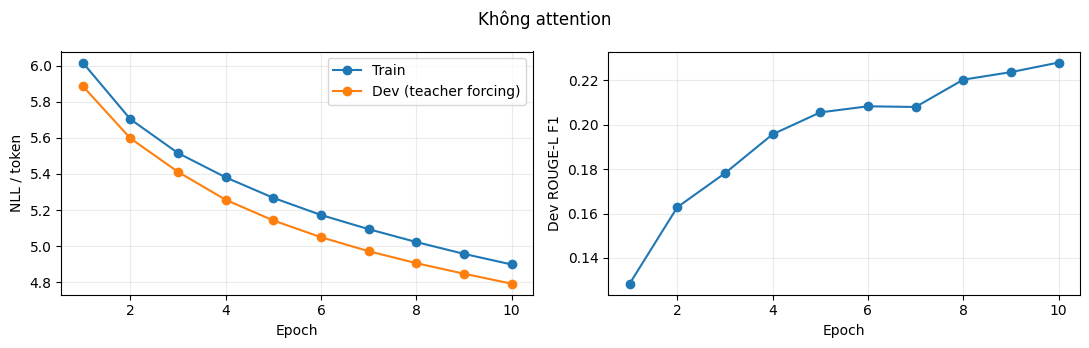

In [37]:
plot_history(histories['none'], 'none')

In [38]:
dev_scores['none'], dev_predictions['none'] = evaluate(model, dev_rows)
display(pd.Series(dev_scores['none']).to_frame('Dev'))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,Dev
rougeL_f1,0.228082
rougeL_precision,0.255671
rougeL_recall,0.208599
bleu,2.255256
bleu_signature,nrefs:1|case:mixed|eff:no|tok:none|smooth:exp|...
dev_nll,4.791424


### Ba câu dịch mẫu

Chọn trên dev ba câu có điểm thấp, trung vị và cao của mô hình Bài 1
(ưu tiên câu nguồn 4–20 token để đọc heatmap). 

In [39]:
all_examples = sentence_examples(dev_rows, dev_predictions['none'])
candidates = all_examples[all_examples.source.str.split().str.len().between(4, 20)]
if len(candidates) < 3:
    candidates = all_examples
candidates = candidates.sort_values(['rougeL', 'id'])
positions = [0, len(candidates) // 2, len(candidates) - 1]
example_ids = candidates.iloc[positions].id.tolist()
by_id = {r['id']: r for r in dev_rows}
example_rows = [by_id[i] for i in example_ids]

In [40]:
examples = sentence_examples(dev_rows, dev_predictions['none'])
examples = examples.set_index('id').loc[example_ids].reset_index()
with pd.option_context('display.max_colwidth', None):
    display(examples)
examples.to_csv(ART / 'none_examples.csv', index=False)

,id,source,reference,translation,rougeL
0,13,several studies show oceans face serious threats,vài nghiên cứu cho thấy các đại dương đối diện với những nguy cơ nghiêm trọng,có thể có có thể có thể của sự phát triển .,0.000000
1,1413,"then the blood is shipped to us , and what we do is extract the dna out of it .","máu được gửi đến chỗ chúng tôi , và điều chúng tôi làm là tách dna khỏi mẫu máu đó .","sau đó , một sự quan trọng , chúng ta , chúng ta , chúng ta , chúng ta là một .",0.232558
2,1636,( laughter ) ( applause ),( cười ) ( vỗ tay ),( tiếng cười ) ( vỗ tay ),0.933333


In [41]:
comment_examples(examples)

Câu 13: ROUGE-L=0.0000; 12/16 token so với tham chiếu.
  Token chung: (không có)
  Token tham chiếu chưa xuất hiện: cho, các, cơ, cứu, diện, dương, nghiêm, nghiên, nguy, những, thấy, trọng, vài, với, đại, đối
Câu 1413: ROUGE-L=0.2326; 22/21 token so với tham chiếu.
  Token chung: ,, ., chúng, là, đó
  Token tham chiếu chưa xuất hiện: chỗ, dna, gửi, khỏi, làm, máu, mẫu, tách, tôi, và, điều, được, đến
Câu 1636: ROUGE-L=0.9333; 8/7 token so với tham chiếu.
  Token chung: (, ), cười, tay, vỗ
  Token tham chiếu chưa xuất hiện: (không có)


In [42]:
del model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

---
## 6. Bài 2 — Bahdanau attention

Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

Decoder truy cập lại memory trước mỗi lần cập nhật LSTM. Context thay đổi theo token đang cần dịch, giúp giảm gánh nặng của vector trạng thái cuối.

In [43]:
seed_all()
model = make_seq2seq('bahdanau')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 8025763


In [44]:
histories['bahdanau'], best_epochs['bahdanau'] = fit(model, 'bahdanau')

  batch 100/582, loss=6.3712
  batch 200/582, loss=6.2332
  batch 300/582, loss=6.1589
  batch 400/582, loss=6.1162
  batch 500/582, loss=6.0729


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bahdanau | epoch 1/10 | loss=6.0432 | dev ROUGE-L=0.1316 | 101 giây train
  batch 100/582, loss=5.7786
  batch 200/582, loss=5.7464
  batch 300/582, loss=5.7231
  batch 400/582, loss=5.6985
  batch 500/582, loss=5.6697


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bahdanau | epoch 2/10 | loss=5.6454 | dev ROUGE-L=0.1948 | 100 giây train
  batch 100/582, loss=5.4311
  batch 200/582, loss=5.4196
  batch 300/582, loss=5.4027
  batch 400/582, loss=5.3921
  batch 500/582, loss=5.3770


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bahdanau | epoch 9/10 | loss=4.5631 | dev ROUGE-L=0.2952 | 101 giây train
  batch 100/582, loss=4.4527
  batch 200/582, loss=4.4593
  batch 300/582, loss=4.4688
  batch 400/582, loss=4.4759
  batch 500/582, loss=4.4782


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bahdanau | epoch 10/10 | loss=4.4809 | dev ROUGE-L=0.2972 | 102 giây train


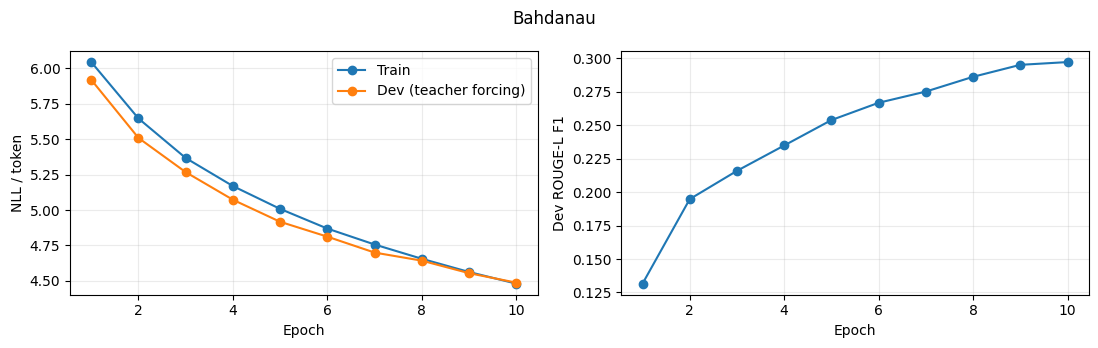

In [45]:
plot_history(histories['bahdanau'], 'bahdanau')

In [46]:
dev_scores['bahdanau'], dev_predictions['bahdanau'] = evaluate(model, dev_rows)
display(pd.Series(dev_scores['bahdanau']).to_frame('Dev'))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,Dev
rougeL_f1,0.297224
rougeL_precision,0.316222
rougeL_recall,0.284408
bleu,4.711528
bleu_signature,nrefs:1|case:mixed|eff:no|tok:none|smooth:exp|...
dev_nll,4.487832


In [47]:
examples = sentence_examples(dev_rows, dev_predictions['bahdanau'])
examples = examples.set_index('id').loc[example_ids].reset_index()
with pd.option_context('display.max_colwidth', None):
    display(examples)
examples.to_csv(ART / 'bahdanau_examples.csv', index=False)

,id,source,reference,translation,rougeL
0,13,several studies show oceans face serious threats,vài nghiên cứu cho thấy các đại dương đối diện với những nguy cơ nghiêm trọng,nhiều nghiên cứu nghiên cứu với những những những những,0.307692
1,1413,"then the blood is shipped to us , and what we do is extract the dna out of it .","máu được gửi đến chỗ chúng tôi , và điều chúng tôi làm là tách dna khỏi mẫu máu đó .","sau đó là phải là chúng ta chúng ta , và chúng ta làm là những thứ của .",0.350000
2,1636,( laughter ) ( applause ),( cười ) ( vỗ tay ),( tiếng cười ) ( vỗ tay ),0.933333


In [48]:
comment_examples(examples)

Câu 13: ROUGE-L=0.3077; 10/16 token so với tham chiếu.
  Token chung: cứu, nghiên, những, với
  Token tham chiếu chưa xuất hiện: cho, các, cơ, diện, dương, nghiêm, nguy, thấy, trọng, vài, đại, đối
Câu 1413: ROUGE-L=0.3500; 19/21 token so với tham chiếu.
  Token chung: ,, ., chúng, là, làm, và, đó
  Token tham chiếu chưa xuất hiện: chỗ, dna, gửi, khỏi, máu, mẫu, tách, tôi, điều, được, đến
Câu 1636: ROUGE-L=0.9333; 8/7 token so với tham chiếu.
  Token chung: (, ), cười, tay, vỗ
  Token tham chiếu chưa xuất hiện: (không có)


ROUGE-L phản ánh phần trùng theo thứ tự token, chưa đủ để kết luận bản
dịch đúng nghĩa. Các token chung hoặc thiếu ở trên giúp đối chiếu; cần
đọc cùng câu nguồn và tham chiếu, nhất là phủ định, tên riêng và số liệu.

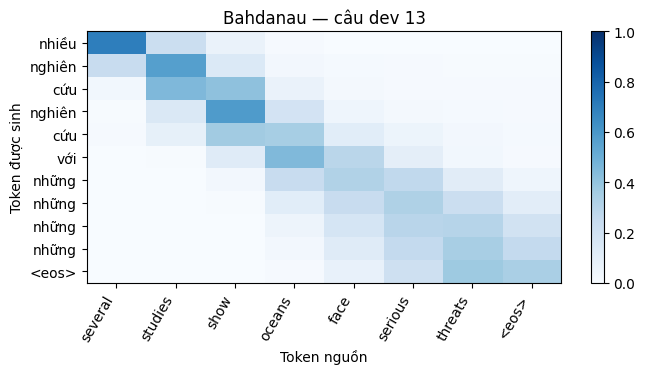

Entropy trung bình: 1.336 nat; mức phân bố đều: 2.079 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['several', 'studies', 'studies', 'show', 'show', 'oceans', 'face', 'serious', 'threats', 'threats', 'threats']


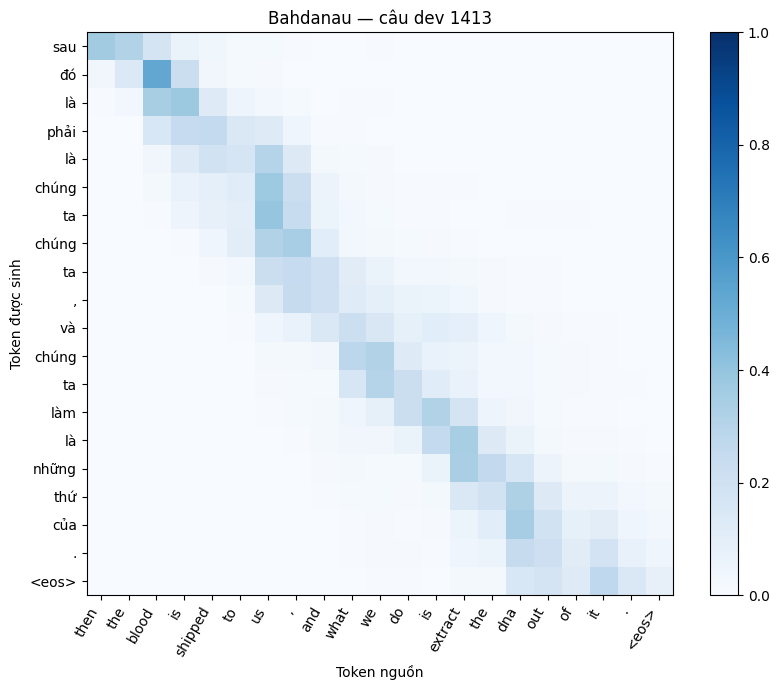

Entropy trung bình: 1.885 nat; mức phân bố đều: 3.045 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['then', 'blood', 'is', 'shipped', 'us', 'us', 'us', ',', ',', ',', 'what', 'we', 'we', 'is', 'extract', 'extract', 'dna', 'dna', 'dna', 'it']


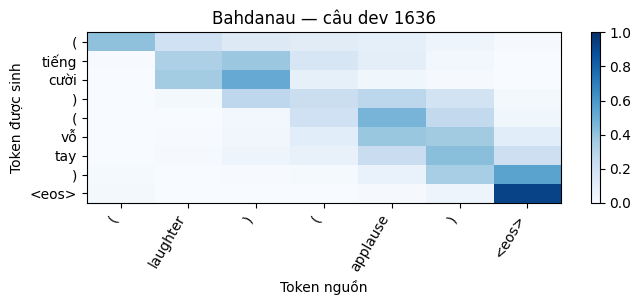

Entropy trung bình: 1.228 nat; mức phân bố đều: 1.946 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['(', ')', ')', 'applause', 'applause', 'applause', ')', '<eos>', '<eos>']


In [49]:
plot_attention(model, example_rows, 'bahdanau')

Entropy gần mức phân bố đều cho thấy attention còn dàn trải; entropy
thấp cho thấy tập trung vào ít vị trí hơn. Chỉ số này không tự chứng minh
dịch đúng. Đọc từng hàng của heatmap để xem token sinh ra đang chú ý vào
đâu, có bỏ sót cụm từ hoặc liên tục tập trung vào EOS hay không.

In [50]:
del model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

---
## 7. Bài 3 — Luong attention

Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

Dùng global-general attention với input-feeding. Query là hidden sau khi cập nhật LSTM; vector attentional được truyền sang bước tiếp theo.

In [51]:
seed_all()
model = make_seq2seq('luong')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 7959971


In [52]:
histories['luong'], best_epochs['luong'] = fit(model, 'luong')

  batch 100/582, loss=6.3814
  batch 200/582, loss=6.2460
  batch 300/582, loss=6.1794
  batch 400/582, loss=6.1400
  batch 500/582, loss=6.1033


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Luong | epoch 1/10 | loss=6.0775 | dev ROUGE-L=0.1264 | 90 giây train
  batch 100/582, loss=5.8444
  batch 200/582, loss=5.8166
  batch 300/582, loss=5.8009
  batch 400/582, loss=5.7853
  batch 500/582, loss=5.7646


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Luong | epoch 2/10 | loss=5.7454 | dev ROUGE-L=0.1683 | 90 giây train
  batch 100/582, loss=5.5779
  batch 200/582, loss=5.5685
  batch 300/582, loss=5.5522
  batch 400/582, loss=5.5409
  batch 500/582, loss=5.5229


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Luong | epoch 9/10 | loss=4.6274 | dev ROUGE-L=0.2831 | 90 giây train
  batch 100/582, loss=4.5069
  batch 200/582, loss=4.5147
  batch 300/582, loss=4.5258
  batch 400/582, loss=4.5306
  batch 500/582, loss=4.5334


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Luong | epoch 10/10 | loss=4.5350 | dev ROUGE-L=0.2916 | 91 giây train


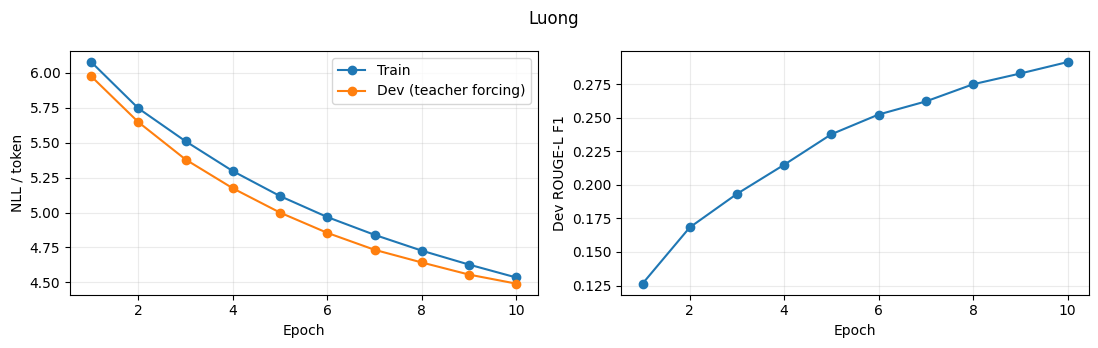

In [53]:
plot_history(histories['luong'], 'luong')

In [54]:
dev_scores['luong'], dev_predictions['luong'] = evaluate(model, dev_rows)
display(pd.Series(dev_scores['luong']).to_frame('Dev'))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,Dev
rougeL_f1,0.291593
rougeL_precision,0.309966
rougeL_recall,0.279237
bleu,4.66592
bleu_signature,nrefs:1|case:mixed|eff:no|tok:none|smooth:exp|...
dev_nll,4.491033


In [55]:
examples = sentence_examples(dev_rows, dev_predictions['luong'])
examples = examples.set_index('id').loc[example_ids].reset_index()
with pd.option_context('display.max_colwidth', None):
    display(examples)
examples.to_csv(ART / 'luong_examples.csv', index=False)

,id,source,reference,translation,rougeL
0,13,several studies show oceans face serious threats,vài nghiên cứu cho thấy các đại dương đối diện với những nguy cơ nghiêm trọng,những nghiên cứu khoa học đã đã được những quan trọng .,0.285714
1,1413,"then the blood is shipped to us , and what we do is extract the dna out of it .","máu được gửi đến chỗ chúng tôi , và điều chúng tôi làm là tách dna khỏi mẫu máu đó .","sau đó là là là chúng ta , chúng ta , và chúng ta đang làm ra những gì .",0.292683
2,1636,( laughter ) ( applause ),( cười ) ( vỗ tay ),( tiếng cười ) ( vỗ tay ),0.933333


In [56]:
comment_examples(examples)

Câu 13: ROUGE-L=0.2857; 12/16 token so với tham chiếu.
  Token chung: cứu, nghiên, những, trọng
  Token tham chiếu chưa xuất hiện: cho, các, cơ, diện, dương, nghiêm, nguy, thấy, vài, với, đại, đối
Câu 1413: ROUGE-L=0.2927; 20/21 token so với tham chiếu.
  Token chung: ,, ., chúng, là, làm, và, đó
  Token tham chiếu chưa xuất hiện: chỗ, dna, gửi, khỏi, máu, mẫu, tách, tôi, điều, được, đến
Câu 1636: ROUGE-L=0.9333; 8/7 token so với tham chiếu.
  Token chung: (, ), cười, tay, vỗ
  Token tham chiếu chưa xuất hiện: (không có)


ROUGE-L phản ánh phần trùng theo thứ tự token, chưa đủ để kết luận bản
dịch đúng nghĩa. Các token chung hoặc thiếu ở trên giúp đối chiếu; cần
đọc cùng câu nguồn và tham chiếu, nhất là phủ định, tên riêng và số liệu.

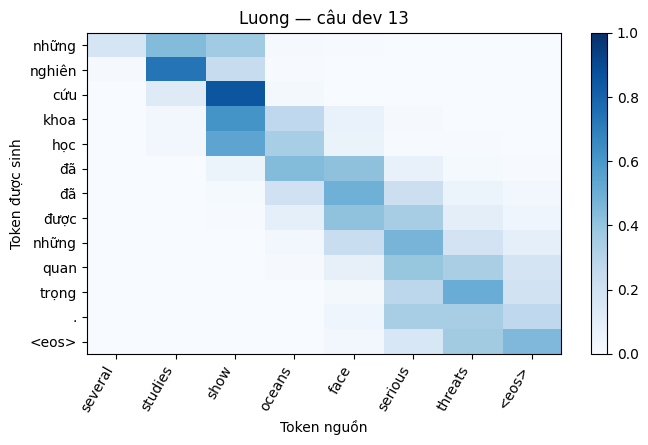

Entropy trung bình: 1.107 nat; mức phân bố đều: 2.079 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['studies', 'studies', 'show', 'show', 'show', 'oceans', 'face', 'face', 'serious', 'serious', 'threats', 'serious', '<eos>']


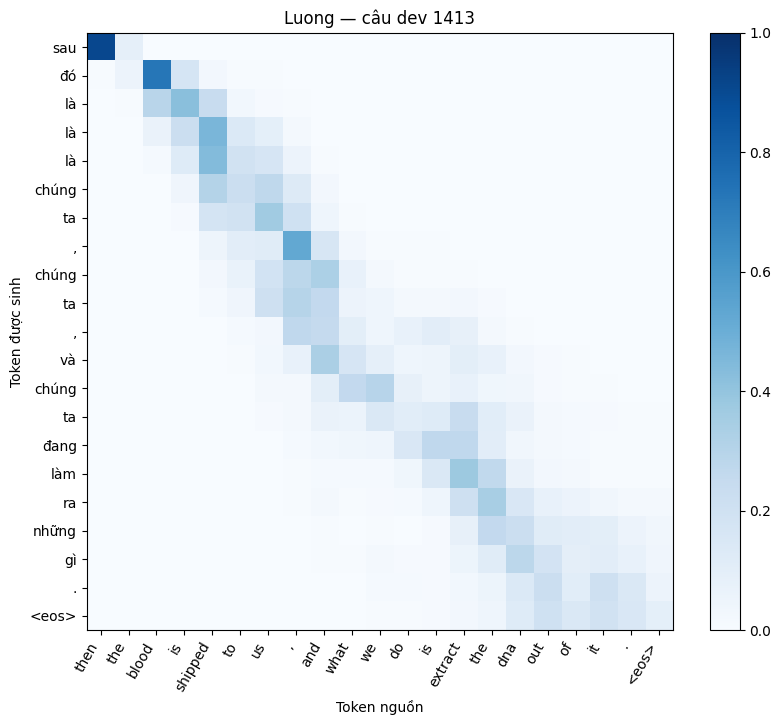

Entropy trung bình: 1.719 nat; mức phân bố đều: 3.045 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['then', 'blood', 'is', 'shipped', 'shipped', 'shipped', 'us', ',', 'and', ',', ',', 'and', 'we', 'extract', 'extract', 'extract', 'the', 'the', 'dna', 'out', 'out']


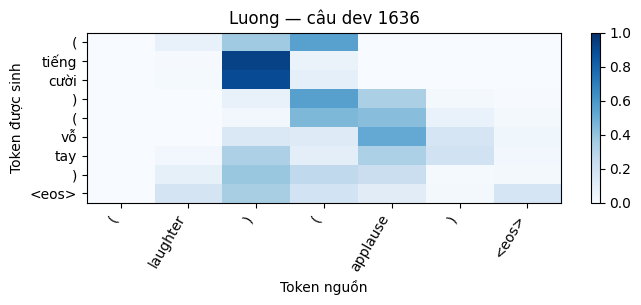

Entropy trung bình: 1.053 nat; mức phân bố đều: 1.946 nat.
Các vị trí nguồn được chú ý nhiều nhất: ['(', ')', ')', '(', '(', 'applause', 'applause', ')', ')']


In [57]:
plot_attention(model, example_rows, 'luong')

Entropy gần mức phân bố đều cho thấy attention còn dàn trải; entropy
thấp cho thấy tập trung vào ít vị trí hơn. Chỉ số này không tự chứng minh
dịch đúng. Đọc từng hàng của heatmap để xem token sinh ra đang chú ý vào
đâu, có bỏ sót cụm từ hoặc liên tục tập trung vào EOS hay không.

In [58]:
del model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

---
## 8. Đánh giá cuối trên test

Các kiến trúc, siêu tham số và checkpoint đã được chốt bằng dev.
Chấm toàn bộ test sau lọc, lưu từng câu dự đoán để có thể đối chiếu.
Không dùng bảng test dưới đây để chọn lại epoch hoặc chỉnh cấu hình.

In [59]:
test_results = []
for mode in names:
    model = make_seq2seq(mode)
    best = torch.load(ART / f'{mode}_best.pt', map_location=device, weights_only=True)
    model.load_state_dict(best['model'])
    score, hypotheses = evaluate(model, filtered['test'], with_loss=False)
    predictions = sentence_examples(filtered['test'], hypotheses)
    predictions['source_length'] = [len(r['src']) for r in filtered['test']]
    predictions.to_csv(ART / f'{mode}_test_predictions.csv', index=False)
    test_results.append(dict(
        model=mode, dev_rougeL=dev_scores[mode]['rougeL_f1'],
        test_rougeL=score['rougeL_f1'], test_bleu=score['bleu'],
        parameters=sum(p.numel() for p in model.parameters()),
        seconds_per_epoch=histories[mode].seconds.mean(),
        best_epoch=best['epoch'], bleu_signature=score['bleu_signature'],
    ))
    del model, best
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
comparison = pd.DataFrame(test_results)
comparison.to_csv(ART / 'comparison.csv', index=False)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


In [60]:
summary = comparison.drop(columns='bleu_signature').copy()
summary['model'] = summary.model.map(names)
summary.columns = ['Mô hình', 'ROUGE-L dev', 'ROUGE-L test', 'BLEU test',
                   'Số tham số', 'Giây/epoch', 'Epoch tốt nhất']
display(summary.round(4))

,Mô hình,ROUGE-L dev,ROUGE-L test,BLEU test,Số tham số,Giây/epoch,Epoch tốt nhất
0,Không attention,0.2281,0.2304,2.4642,7500963,66.1687,10
1,Bahdanau,0.2972,0.3105,5.9342,8025763,100.9617,10
2,Luong,0.2916,0.3001,5.4823,7959971,90.5289,10


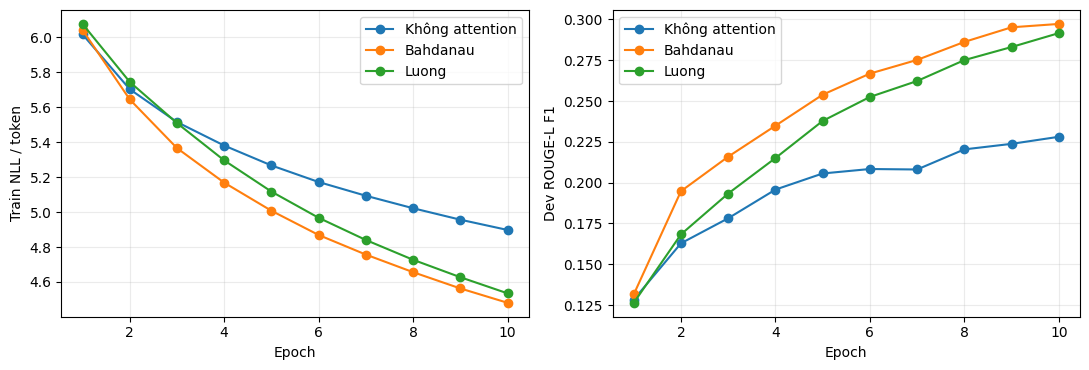

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for mode, history in histories.items():
    axes[0].plot(history.epoch, history.train_loss, marker='o', label=names[mode])
    axes[1].plot(history.epoch, history.rougeL_f1, marker='o', label=names[mode])
axes[0].set_ylabel('Train NLL / token')
axes[1].set_ylabel('Dev ROUGE-L F1')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(ART / 'comparison_curves.png', dpi=160)
plt.show()

### Chất lượng theo độ dài câu nguồn

In [62]:
length_records = []
for mode in names:
    frame = pd.read_csv(ART / f'{mode}_test_predictions.csv', keep_default_na=False)
    frame['length_group'] = pd.cut(frame.source_length, [0, 10, 20, 30, 50],
                                  labels=['1–10', '11–20', '21–30', '31–50'])
    for group, part in frame.groupby('length_group', observed=True):
        length_records.append(dict(model=names[mode], length=str(group),
                                   sentences=len(part), rougeL=part.rougeL.mean()))
length_scores = pd.DataFrame(length_records)
display(length_scores.pivot(index='length', columns='model', values='rougeL').round(4))
length_scores.to_csv(ART / 'rouge_by_length.csv', index=False)

model,Bahdanau,Không attention,Luong
length,,,
11–20,0.3181,0.2357,0.3046
1–10,0.3990,0.3360,0.3946
21–30,0.2741,0.1896,0.2647
31–50,0.2544,0.1677,0.2423


### Nhận xét từ lần chạy

In [63]:
ranked = comparison.sort_values('test_rougeL', ascending=False)
winner = ranked.iloc[0]
print(f'{names[winner.model]} có ROUGE-L test cao nhất trong lần chạy này: '
      f'{winner.test_rougeL:.4f}.')
baseline = comparison.set_index('model').loc['none', 'test_rougeL']
for mode in ['bahdanau', 'luong']:
    row = comparison.set_index('model').loc[mode]
    delta = row.test_rougeL - baseline
    print(f'{names[mode]} chênh {delta:+.4f} so với mô hình không attention; '
          f'{row.seconds_per_epoch:.1f} giây/epoch.')
for mode, history in histories.items():
    best_index = int(history.rougeL_f1.idxmax())
    print(f'{names[mode]}: train loss {history.train_loss.iloc[0]:.4f} → '
          f'{history.train_loss.iloc[-1]:.4f}; checkpoint chọn ở epoch {best_epochs[mode]}.')
    if history.rougeL_f1.iloc[-1] < history.rougeL_f1.iloc[best_index]:
        print('  ROUGE-L dev cuối thấp hơn mức cao nhất, nên dùng checkpoint đã lưu.')

Bahdanau có ROUGE-L test cao nhất trong lần chạy này: 0.3105.
Bahdanau chênh +0.0801 so với mô hình không attention; 101.0 giây/epoch.
Luong chênh +0.0697 so với mô hình không attention; 90.5 giây/epoch.
Không attention: train loss 6.0179 → 4.8979; checkpoint chọn ở epoch 10.
Bahdanau: train loss 6.0432 → 4.4809; checkpoint chọn ở epoch 10.
Luong: train loss 6.0775 → 4.5350; checkpoint chọn ở epoch 10.


Attention cho decoder truy cập toàn bộ câu nguồn, có thể giúp giữ chi
tiết trên câu dài. Bảng theo độ dài ở trên cho phép đối chiếu điều này
trên chính lần chạy. Bahdanau và Luong khác cả cách chấm điểm lẫn vị trí
đưa context vào decoder, nên chênh lệch không chỉ do một phép cộng hay nhân.

Kết quả còn phụ thuộc từ ngoài từ điển, tách token theo khoảng trắng,
greedy decoding và giới hạn 10 epoch. Một seed chưa đủ để kết luận mô
hình nào luôn tốt hơn. 